### Notebook for EDA

In [1]:
import numpy as np
import pandas as  pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer

In [2]:
df = pd.read_csv("data/movie.csv")

In [3]:
df=df.drop(columns="Poster_Link")

In [27]:
df.head(5)

,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,IMDb_100,Difference,decade
0,The Shawshank Redemption,1994.0,A,2.37,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110.0,28341469.0,93.0,13.0,1990
1,The Godfather,1972.0,A,2.92,Crime,9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367.0,134966411.0,92.0,-8.0,1970
1,The Godfather,1972.0,A,2.92,Drama,9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367.0,134966411.0,92.0,-8.0,1970
2,The Dark Knight,2008.0,UA,2.53,Action,9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232.0,534858444.0,90.0,6.0,2000
2,The Dark Knight,2008.0,UA,2.53,Crime,9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232.0,534858444.0,90.0,6.0,2000


In [5]:
df.isna().sum()

Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Series_Title   1000 non-null   str    
 1   Released_Year  1000 non-null   str    
 2   Certificate    899 non-null    str    
 3   Runtime        1000 non-null   str    
 4   Genre          1000 non-null   str    
 5   IMDB_Rating    1000 non-null   float64
 6   Overview       1000 non-null   str    
 7   Meta_score     843 non-null    float64
 8   Director       1000 non-null   str    
 9   Star1          1000 non-null   str    
 10  Star2          1000 non-null   str    
 11  Star3          1000 non-null   str    
 12  Star4          1000 non-null   str    
 13  No_of_Votes    1000 non-null   int64  
 14  Gross          831 non-null    str    
dtypes: float64(2), int64(1), str(12)
memory usage: 117.3 KB


In [7]:
df["Runtime"]=(df["Runtime"].str.replace('min','').astype(float)/60).round(2)

In [8]:
df["Gross"] = df["Gross"].str.replace("$", "", regex=False)
df["Gross"] = df["Gross"].str.replace(",", "", regex=False).astype(float)
df["Gross"]=df["Gross"].astype(float)
df["No_of_Votes"]=df["No_of_Votes"].astype(float)
df["Released_Year"] = pd.to_numeric(df["Released_Year"], errors="coerce")

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Series_Title   1000 non-null   str    
 1   Released_Year  999 non-null    float64
 2   Certificate    899 non-null    str    
 3   Runtime        1000 non-null   float64
 4   Genre          1000 non-null   str    
 5   IMDB_Rating    1000 non-null   float64
 6   Overview       1000 non-null   str    
 7   Meta_score     843 non-null    float64
 8   Director       1000 non-null   str    
 9   Star1          1000 non-null   str    
 10  Star2          1000 non-null   str    
 11  Star3          1000 non-null   str    
 12  Star4          1000 non-null   str    
 13  No_of_Votes    1000 non-null   float64
 14  Gross          831 non-null    float64
dtypes: float64(6), str(9)
memory usage: 117.3 KB


In [10]:
df['Meta_score'] = df['Meta_score'].fillna(
    df.groupby('Released_Year')['Meta_score'].transform('median')
)
df['Gross'] = df['Gross'].fillna(
    df.groupby('Genre')['Gross'].transform('median')
)
df['Meta_score'] = df['Meta_score'].fillna(df['Meta_score'].median())
df['Gross'] = df['Gross'].fillna(df['Gross'].median())


imputer = SimpleImputer(strategy='median')

df[['IMDB_Rating']] = imputer.fit_transform(df[['IMDB_Rating']])

In [11]:
df = df.dropna(subset=["Released_Year"])

In [12]:
df["Genre"]=df["Genre"].str.split(',')

In [13]:
df = df.explode("Genre")

### Now Creating and saving Graphs as PNG ###

IMDB Rating Distribution


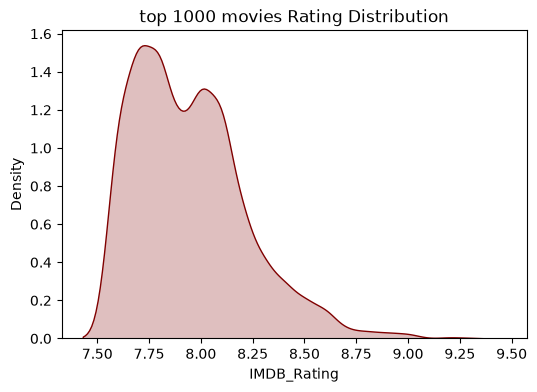

In [14]:
plt.figure(figsize=(6, 4))
sns.kdeplot(data=df, x="IMDB_Rating", fill=True, color="maroon")
plt.title("top 1000 movies Rating Distribution")
plt.show()


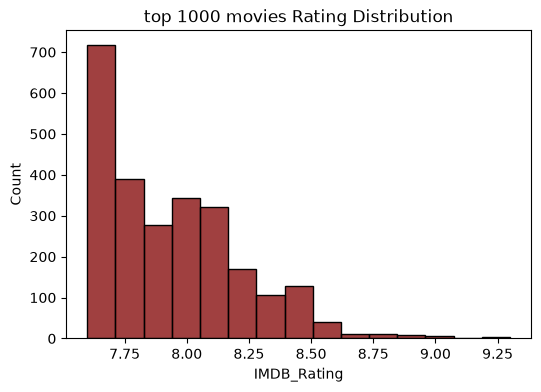

In [15]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="IMDB_Rating", fill=True, color="maroon",bins=15)
plt.title("top 1000 movies Rating Distribution")
plt.show()

Now Creating Graphs to differentiate cult classic and Critic darlings


In [16]:
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette=["#36CFC9", "#F4C95D", "#FF6B6B", "#8B7CFF"],
    rc={
        "figure.facecolor": "#141821",
        "axes.facecolor": "#202735",
        "axes.edgecolor": "#394354",
        "axes.labelcolor": "#E7EAF0",
        "text.color": "#F4F4F5",
        "xtick.color": "#B8C0CC",
        "ytick.color": "#B8C0CC",
        "grid.color": "#394354",
        "grid.alpha": 0.45,
        "axes.titleweight": "bold",
        "axes.titlesize": 16,
        "axes.labelsize": 11,
        "figure.titlesize": 20,
    }
)

In [17]:
df["IMDb_100"] = df["IMDB_Rating"] * 10
df["Difference"] = df["IMDb_100"] - df["Meta_score"]

cult_classic =(df.drop_duplicates(subset="Series_Title").nlargest(5,'Difference'))
critics =(df.drop_duplicates(subset="Series_Title").nsmallest(5,'Difference'))

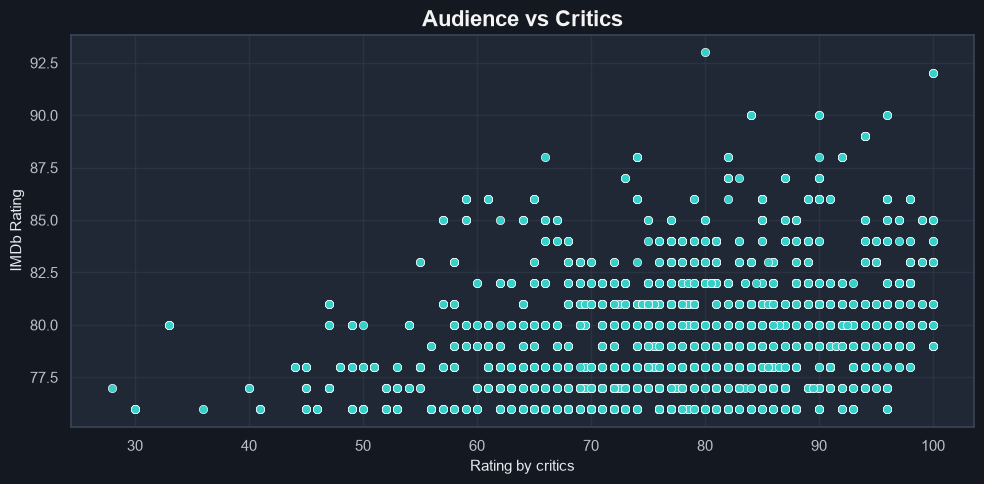

In [18]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=df,
    y="IMDb_100",
    x="Meta_score"
)
plt.title("Audience vs Critics")
plt.ylabel("IMDb Rating")
plt.xlabel("Rating by critics")
plt.tight_layout()
plt.show()

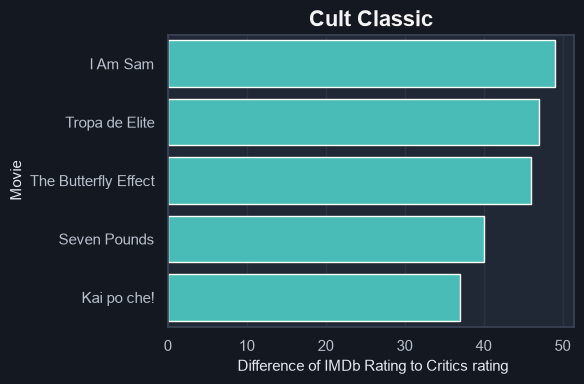

In [19]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=cult_classic,
    x="Difference",
    y="Series_Title"
)
plt.title("Cult Classic")
plt.xlabel(" Difference of IMDb Rating to Critics rating")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()

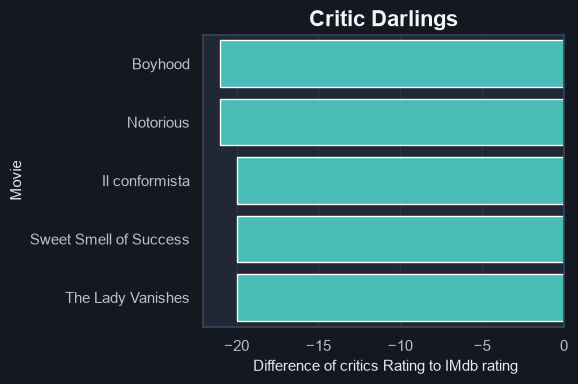

In [20]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=critics,
    x="Difference",
    y="Series_Title"
)
plt.title("Critic Darlings")
plt.xlabel(" Difference of critics Rating to IMdb rating")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()

Now Average rating per decade

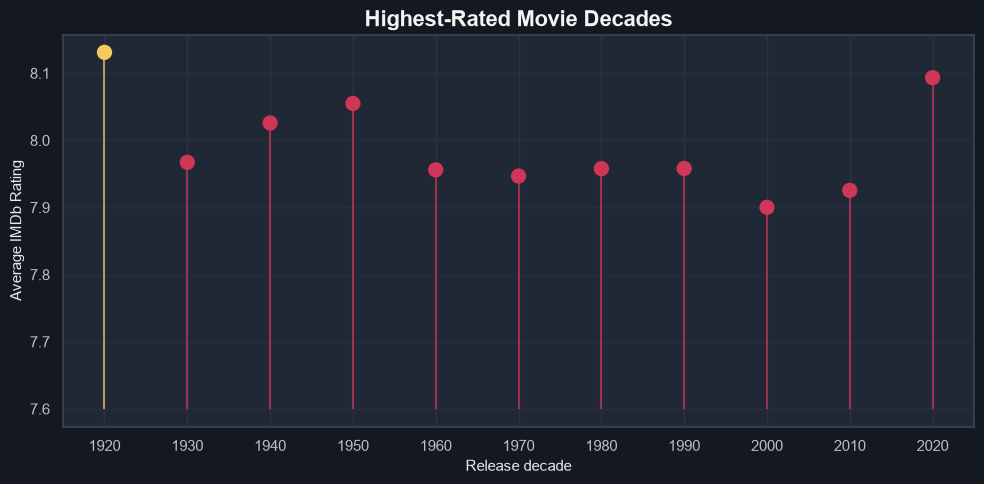

In [21]:
df['decade']=(df["Released_Year"]//10)*10
df["decade"]=df['decade'].astype("int")

decade_rating=(df.groupby("decade")["IMDB_Rating"].mean().reset_index())
plt.figure(figsize=(10, 5))

highest_decade = decade_rating.loc[
    decade_rating["IMDB_Rating"].idxmax(), "decade"
]

colors = [
    "#F4C95D" if d == highest_decade else "#CF3657"
    for d in decade_rating["decade"]
]

plt.vlines(
    x=decade_rating["decade"],
    ymin=decade_rating["IMDB_Rating"].min() - 0.3,
    ymax=decade_rating["IMDB_Rating"],
    color=colors,
    alpha=0.7
)

plt.scatter(
    decade_rating["decade"],
    decade_rating["IMDB_Rating"],
    color=colors,
    s=100,
    zorder=3
)

plt.xticks(decade_rating["decade"])
plt.ylabel("Average IMDb Rating")
plt.xlabel("Release decade")
plt.title("Highest-Rated Movie Decades")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

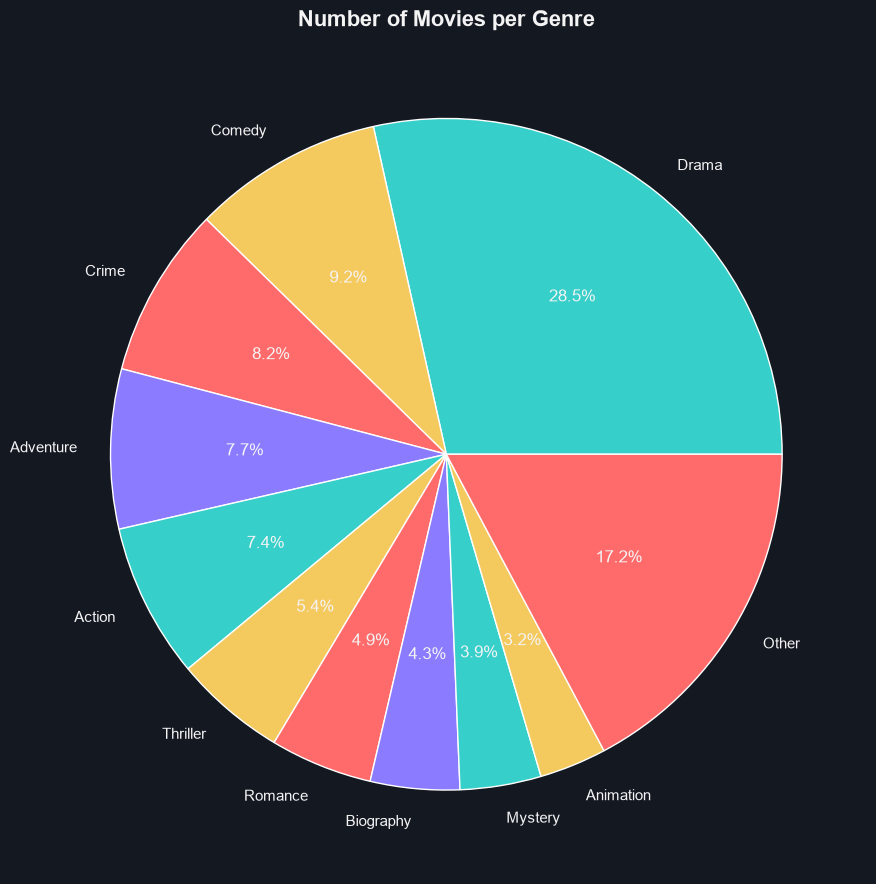

In [22]:
plt.close("all")
genre_counts = (
    df["Genre"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)
top_10 = genre_counts.head(10)
others = genre_counts.iloc[10:].sum()

plot_counts = pd.concat([
    top_10,
    pd.Series({"Other": others})
])

plt.figure(figsize=(9, 9))
plt.pie(
    plot_counts.values,
    labels=plot_counts.index,
    autopct="%1.1f%%",
)

plt.title("Number of Movies per Genre")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

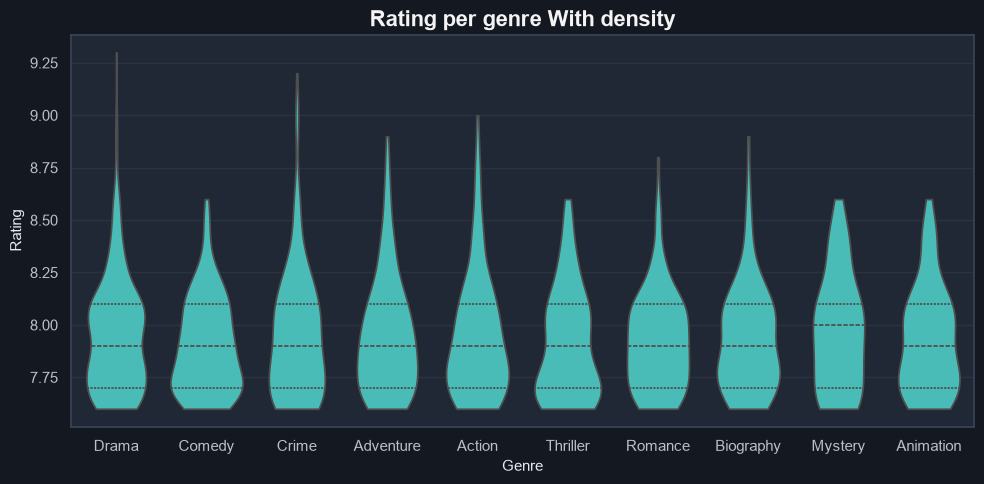

In [23]:
plt.figure(figsize=(10,5))
genre_df = (
    df.dropna(subset=["Genre", "IMDB_Rating"])
      .assign(Genre=lambda x: x["Genre"].str.split(","))
      .explode("Genre")
)
genre_df["Genre"] = genre_df["Genre"].str.strip()
genre_counts = genre_df["Genre"].value_counts()
top_10 = genre_counts.head(10).index
plot_df = genre_df[genre_df["Genre"].isin(top_10)]

sns.violinplot(data=plot_df,
    x="Genre",
    y="IMDB_Rating",
    order=top_10,
    inner="quartile",
    cut=0)

plt.title("Rating per genre With density")
plt.xlabel("Genre")
plt.ylabel("Rating")
plt.tight_layout()
plt.show

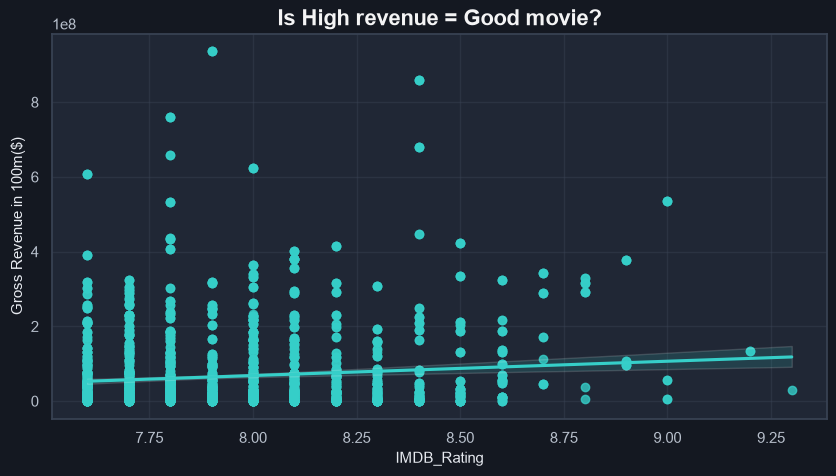

In [29]:
plt.figure(figsize=(10, 5))

sns.regplot(data=df, x="IMDB_Rating", y="Gross")
plt.title("Is High revenue = Good movie?")
plt.ylabel("Gross Revenue in 100m($)")
plt.show()

In [32]:
total_movies = df["Series_Title"].nunique()
avg_imdb = df["IMDB_Rating"].mean()
avg_metascore = df["Gross"].mean()
years = pd.to_numeric(df["Released_Year"], errors="coerce")
oldest_year = int(years.min())
newest_year = int(years.max())
print(f"Total Movies Analyzed: {total_movies}")
print(f"Average IMDb Rating: {avg_imdb:.2f}/10")
print(f"Average Gross: {avg_metascore:.2f}")
print(f"Release Year Range: {oldest_year} – {newest_year}")

Total Movies Analyzed: 998
Average IMDb Rating: 7.95/10
Average Gross: 66246320.52
Release Year Range: 1920 – 2020
